# 61장 · FastMCP 도구 등록과 클라이언트 호출

MCP 서버는 호출할 수 있는 도구 목록과 각 도구의 입력 형식을 알립니다. 클라이언트는 도구 이름과 인자를 지정해 결과를 받습니다.

도서관 시간표 함수는 이미 있습니다. 다른 프로그램에서 함수의 이름과 인자를 먼저 알아내고 같은 결과를 받을 수 있을까요? MCP 서버에 함수를 등록하고, 실제 MCP 클라이언트에서 목록 조회와 호출을 차례로 실행합니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 mcp 1.30.0입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## FastMCP의 tool() 데코레이터

서버는 조회 함수를 소유합니다. 클라이언트는 서버의 목록에서 어떤 도구를 부를 수 있는지 확인합니다. 이 노트북은 MCP Python SDK의 메모리 전송을 사용합니다. 별도 프로세스를 띄우는 stdio와 외부 주소에 연결하는 HTTP는 장별 참고 구현에서 다룹니다.


### 셀 01 · FastMCP 서버와 도구 등록

수업용 MCP 1.x 커널에서 실행합니다. @server.tool()이 함수의 이름, 설명, day의 허용값을 도구 명세에 반영합니다.

직접 함수 호출에서는 반환한 운영 시간을 확인합니다. SDK 메모리 전송에서는 세션을 통해 받은 도구 결과를 읽습니다. 별도 프로세스로 서버를 띄우는 stdio는 또 다른 경로입니다. 메모리 전송의 성공만으로 stdio 연결까지 성공했다고 기록하지 않습니다.


In [1]:
from typing import Literal
from mcp.server.fastmcp import FastMCP
from mcp.shared.memory import create_connected_server_and_client_session

server = FastMCP("course-library-v1", log_level="ERROR")
hours = {"weekday": "09:00~18:00", "weekend": "10:00~16:00"}

@server.tool()
def get_library_hours(day: Literal["weekday", "weekend"]) -> dict[str, str]:
    """가상 도서관의 평일 또는 주말 운영 시간을 조회합니다."""
    return {"day": day, "hours": hours[day], "source": "수업용 가상 도서관"}
print(get_library_hours('weekend')['hours'])

10:00~16:00


10:00~16:00은 Python 함수를 직접 호출한 결과입니다. 여기까지는 아직 클라이언트가 서버에 요청한 적이 없습니다.


### 같은 함수의 기준 결과

<p>Python에서 get_library_hours('weekend')를 직접 부르면 10:00~16:00을 읽을 수 있습니다. 뒤의 세션 호출에서 같은 요일이 같은 값을 내는지 비교할 기준입니다.</p>


### 셀 02 · list_tools()로 명세 조회

연결 도우미가 세션을 열고 초기화합니다. 목록 조회에는 day를 보내지 않습니다.


In [2]:
async with create_connected_server_and_client_session(server) as session:
    catalog = await session.list_tools()
print(catalog.tools[0].name)

get_library_hours


get_library_hours가 보입니다. 이름을 알았지만 아직 운영 시간은 받지 않았습니다. async with가 끝나면 이 세션도 닫힙니다.


### 도구를 제공하는 쪽과 호출하는 쪽

<p>서버에는 get_library_hours가 등록되어 있습니다. 클라이언트는 세션으로 도구의 명세를 조회하거나 인자를 담아 호출합니다. 이 노트북의 연결은 메모리 안에서 이루어집니다.</p>


### 목록 조회와 실제 호출

<p>list_tools()가 돌려주는 것은 호출 가능한 도구의 명세입니다. 운영 시간을 받으려면 새로 연 세션의 call_tool()에 이름과 day 값을 함께 보냅니다.</p>

<h3>메모리 세션에서 조회할 수 있는 두 결과</h3>

<p>셀 02의 세션에서 list_tools()가 반환한 첫 명세의 이름은 get_library_hours입니다. 셀 03에서는 새 메모리 세션을 열고 같은 이름과 day="weekend"를 call_tool에 보냅니다. 이번에는 도구 명세 대신 weekend와 10:00~16:00이 담긴 structuredContent를 읽습니다.</p>


## list_tools()와 call_tool()

call_tool은 도구 이름과 인자 사전을 보냅니다. await 뒤에는 서버가 보낸 결과가 돌아옵니다. 아래처럼 structuredContent를 읽으면 텍스트를 다시 파싱할 필요가 없습니다.

<!-- lesson-visual visual-call -->
**목록 조회 뒤에야 실제 운영 시간을 묻습니다**

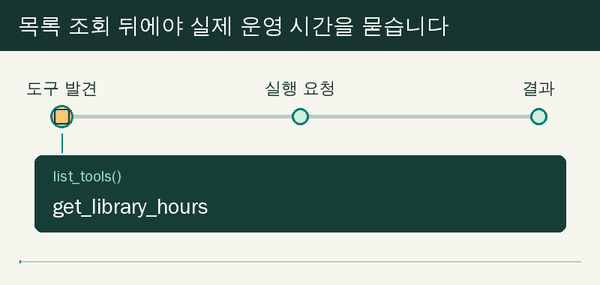

list_tools()는 사용 가능한 이름을 알려 줍니다. 그 이름과 weekend 인자를 call_tool()로 보내면 주말 시간 값이 돌아옵니다.
<!-- /lesson-visual visual-call -->


### 세션을 통해 MCP 도구의 구조화 결과 받기

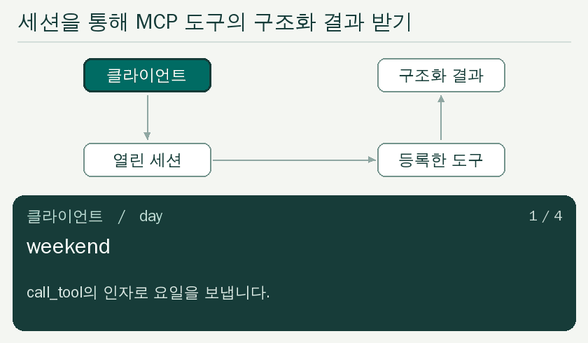

이 호출은 노트북 안의 메모리 연결을 사용합니다. 목록 조회 결과인 도구 이름과 실제 호출 결과를 비교하세요.


### 셀 03 · call_tool()의 구조화 결과

호출을 열린 세션 안에 두고, 결과가 어느 요일에 대한 것인지 확인하세요.


In [3]:
async with create_connected_server_and_client_session(server) as session:
    reply = await session.call_tool("get_library_hours", {"day": "weekend"})
print(reply.structuredContent["day"], reply.structuredContent["hours"])

weekend 10:00~16:00


weekend와 10:00~16:00이 함께 돌아옵니다. 입력의 요일이 결과의 요일과 맞는지 대조할 수 있습니다.


### 구조화된 필드에서 응답 읽기

<p>reply.structuredContent에서 day와 hours를 각각 읽습니다. 출력 첫 값이 weekend인지 먼저 보면, 다른 요일의 시간을 실수로 주말 응답으로 읽는 일을 피할 수 있습니다.</p>


### 과제 04 · 요일 인자를 바꿔 도구 호출

인자 하나를 바꾸어 평일 운영 시간을 읽으세요. 이름 목록 조회만으로 끝내지 마세요.


In [4]:
# 새 세션에서 weekday를 요청하고 hours를 출력하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>async with create_connected_server_and_client_session(server) as session:
    reply = await session.call_tool(&#x27;get_library_hours&#x27;, {&#x27;day&#x27;: &#x27;weekday&#x27;})
print(reply.structuredContent[&#x27;hours&#x27;])</code></pre>
<p>실행 결과</p><pre><code>09:00~18:00</code></pre>
<p>09:00~18:00입니다. 수업용 메모리 전송 안에서 클라이언트와 서버가 실제로 교환한 값입니다. 외부 도서관의 현재 운영 시간을 확인한 결과는 아닙니다. 별도 프로세스를 쓰는 경우는 클라이언트를 연결하기 전에 서버가 실행 중인지 확인하세요.</p>
</details>


## 돌아보기

함수 이름이 목록에 없을 때는 등록과 목록 조회를, 올바른 이름이 있는데 운영 시간이 틀리면 인자와 실제 시간표 함수를 먼저 살펴보세요.

### 별도 프로세스로 연결하는 stdio 예제

**서버 프로세스 시작**　현재 Python 실행기로 server_stdio.py를 시작합니다.

```
StdioServerParameters
```

**초기화**　이 버전의 연결에서 지원 기능을 확인합니다.

```
session.initialize()
```

**도구 목록 확인**　이름이 get_library_hours 하나인지 확인합니다.

```
session.list_tools()
```

**함수 실행과 결과**　day를 받아 시간표 결과를 반환합니다.

```
클라이언트: session.call_tool(…)
서버: get_library_hours(day="weekend")
```

**결과 검사와 종료**　구조화 결과를 검사하고 세션·프로세스를 정리합니다.

```
normalize_result → context 종료
```
